[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Shreyashgol/phonetic-guided-speech-generation/blob/main/notebooks/11_acoustic_model.ipynb)

# 11 · The acoustic model (FastSpeech 2-style)
**Goal:** build the model that turns *phonemes + durations* into a mel spectrogram, and **prove it is wired correctly before any long training** (notebook 12 trains it).

**Pipeline in this notebook**
`phoneme + stress embeddings → encoder (4 FFT blocks) → duration head → length regulator → decoder (4 FFT blocks) → 80-bin mel`

**Design decisions (put these in the report)**
- **Durations are an input, not a guess.** In training the length regulator uses the MFA ground-truth durations (teacher forcing). At inference it can use **three** duration sources: ground truth, the model's own duration head, or **our Phase 1 BiLSTM**. Comparing them in notebook 14 is the Phase 1 → Phase 2 link.
- **Small on purpose** (about 8M parameters, 256 hidden units) so it trains on a free Colab GPU within a few sessions.
- **No pitch/energy predictors yet.** FastSpeech 2 adds them; we start without and add them as an ablation if time allows.
- **FFT block** = multi-head self-attention + 1D-conv feed-forward + residual + LayerNorm. Convolutions matter here because neighbouring phones affect each other.
- **Loss** = masked L1 on the (normalised) mel + masked MSE on `log(duration + 1)` for the model's own duration head. Padding never contributes.

**Reads:** `phase2_manifest.csv`, mels, `mel_stats.json` (notebook 10). **Writes:** `src/models/acoustic/model.py`, `src/data/tts_dataset.py`, `results/11_overfit_check.png`.

In [ ]:
import torch

print("CUDA Available:", torch.cuda.is_available())

CUDA Available: True


In [ ]:
# ---- Cell 0: Setup (identical at the top of every notebook)
import os, sys, json, glob
try:
    from google.colab import drive
    drive.mount('/content/drive')
    PROJECT_ROOT = '/content/drive/MyDrive/phonetic-tts'
    IN_COLAB = True
except ImportError:                      # running somewhere else (local / tests)
    PROJECT_ROOT = os.environ.get('PROJECT_ROOT', os.getcwd())
    IN_COLAB = False
sys.path.insert(0, PROJECT_ROOT)
from src.utils.config import load_config
cfg = load_config(PROJECT_ROOT)
A = cfg['audio']; P = cfg['abs_paths']
RAW, PROCESSED, ALIGN, SPLITS, RESULTS = P['raw'], P['processed'], P['alignments'], P['splits'], P['results']
for d in (PROCESSED, ALIGN, SPLITS, RESULTS):
    os.makedirs(d, exist_ok=True)
print('Project root:', PROJECT_ROOT, '| Colab:', IN_COLAB)

Mounted at /content/drive
Project root: /content/drive/MyDrive/phonetic-tts | Colab: True


## Step 1: Write the shared modules (used again by notebooks 12–14)

In [ ]:
# ---- Write shared module: Phase 2 dataset, collate and bucket sampler
import os, importlib
_src = r'''"""Phase 2 data loading: manifest + mels from notebook 10."""
import json, os
import numpy as np, pandas as pd, torch
from torch.utils.data import Dataset, Sampler


class TTSDataset(Dataset):
    def __init__(self, processed_dir, split, max_items=None):
        df = pd.read_csv(os.path.join(processed_dir, 'phase2_manifest.csv'))
        df = df[df.split == split].reset_index(drop=True)
        if max_items: df = df.iloc[:max_items]
        st = json.load(open(os.path.join(processed_dir, 'mel_stats.json')))
        self.mean = np.array(st['mean'], np.float32); self.std = np.array(st['std'], np.float32) + 1e-5
        self.mel_dir = os.path.join(processed_dir, 'mels')
        self.ids = df.utt_id.tolist(); self.n_frames = df.n_frames.to_numpy()
        self.tokens = [np.array(s.split(), np.int64) for s in df.tokens]
        self.stress = [np.array(s.split(), np.int64) for s in df.stress]
        self.durs = [np.array(s.split(), np.int64) for s in df.durations]

    def __len__(self):
        return len(self.ids)

    def mel(self, i):
        m = np.load(os.path.join(self.mel_dir, self.ids[i] + '.npy')).astype(np.float32)
        return (m - self.mean) / self.std

    def __getitem__(self, i):
        return dict(id=self.ids[i], tok=torch.from_numpy(self.tokens[i]), stress=torch.from_numpy(self.stress[i]),
                    dur=torch.from_numpy(self.durs[i]), mel=torch.from_numpy(self.mel(i)))


def collate(batch):
    B = len(batch); T = max(len(b['tok']) for b in batch); M = max(len(b['mel']) for b in batch)
    n_mels = batch[0]['mel'].shape[1]
    tok = torch.zeros(B, T, dtype=torch.long); st = torch.zeros(B, T, dtype=torch.long)
    dur = torch.zeros(B, T, dtype=torch.long); mel = torch.zeros(B, M, n_mels)
    for i, b in enumerate(batch):
        t, m = len(b['tok']), len(b['mel'])
        tok[i, :t] = b['tok']; st[i, :t] = b['stress']; dur[i, :t] = b['dur']; mel[i, :m] = b['mel']
    return dict(ids=[b['id'] for b in batch], tok=tok, stress=st, dur=dur, mel=mel,
                mel_len=torch.tensor([len(b['mel']) for b in batch]))


class BucketSampler(Sampler):
    """Batches of similar length (less padding), shuffled each epoch."""
    def __init__(self, n_frames, batch_size, shuffle=True, seed=0):
        self.n = np.asarray(n_frames); self.bs = batch_size; self.shuffle = shuffle; self.epoch = 0; self.seed = seed

    def __iter__(self):
        rng = np.random.RandomState(self.seed + self.epoch); self.epoch += 1
        idx = rng.permutation(len(self.n)) if self.shuffle else np.arange(len(self.n))
        chunk = self.bs * 50
        batches = []
        for s in range(0, len(idx), chunk):
            c = idx[s:s + chunk]; c = c[np.argsort(self.n[c])]
            batches += [c[j:j + self.bs].tolist() for j in range(0, len(c), self.bs)]
        if self.shuffle: rng.shuffle(batches)
        return iter(batches)

    def __len__(self):
        return (len(self.n) + self.bs - 1) // self.bs
'''
_p = os.path.join(PROJECT_ROOT, "src/data/tts_dataset.py")
os.makedirs(os.path.dirname(_p), exist_ok=True)
for _d in ["src", os.path.dirname("src/data/tts_dataset.py")]:
    open(os.path.join(PROJECT_ROOT, _d, "__init__.py"), "a").close()
open(_p, "w").write(_src)
importlib.invalidate_caches()
print("wrote", _p)

wrote /content/drive/MyDrive/phonetic-tts/src/data/tts_dataset.py


In [ ]:
# ---- Write shared module: FastSpeech 2-style acoustic model + loss
import os, importlib
_src = r'''"""FastSpeech 2-style acoustic model (phonemes + durations -> mel). No pitch/energy predictors (added later as an ablation)."""
import math
import torch, torch.nn as nn, torch.nn.functional as F
from torch.nn.utils.rnn import pad_sequence


def sinusoid(n, d):
    pos = torch.arange(n).unsqueeze(1).float()
    ang = pos / torch.pow(10000.0, torch.arange(0, d, 2).float() / d)
    pe = torch.zeros(n, d); pe[:, 0::2] = torch.sin(ang); pe[:, 1::2] = torch.cos(ang)
    return pe


class FFTBlock(nn.Module):
    """Self-attention + 1D-conv feed-forward, post-LayerNorm (as in FastSpeech)."""
    def __init__(self, d, heads, ffn, k, p):
        super().__init__()
        self.attn = nn.MultiheadAttention(d, heads, dropout=p, batch_first=True)
        self.n1, self.n2 = nn.LayerNorm(d), nn.LayerNorm(d)
        self.c1 = nn.Conv1d(d, ffn, k, padding=k // 2); self.c2 = nn.Conv1d(ffn, d, 1)
        self.drop = nn.Dropout(p)

    def forward(self, x, pad):                       # x (B,T,D); pad (B,T) True = padding
        a, _ = self.attn(x, x, x, key_padding_mask=pad, need_weights=False)
        x = self.n1(x + self.drop(a))
        y = x.masked_fill(pad.unsqueeze(-1), 0).transpose(1, 2)
        y = self.c2(F.relu(self.c1(y))).transpose(1, 2)
        x = self.n2(x + self.drop(y))
        return x.masked_fill(pad.unsqueeze(-1), 0)


class DurationPredictor(nn.Module):
    """Predicts log(frames + 1) per token (the model's own duration head)."""
    def __init__(self, d, k=3, p=0.2):
        super().__init__()
        self.c1 = nn.Conv1d(d, d, k, padding=k // 2); self.n1 = nn.LayerNorm(d)
        self.c2 = nn.Conv1d(d, d, k, padding=k // 2); self.n2 = nn.LayerNorm(d)
        self.out = nn.Linear(d, 1); self.drop = nn.Dropout(p)

    def forward(self, x, pad):
        m = pad.unsqueeze(-1)
        y = self.drop(self.n1(F.relu(self.c1(x.masked_fill(m, 0).transpose(1, 2))).transpose(1, 2)))
        y = self.drop(self.n2(F.relu(self.c2(y.masked_fill(m, 0).transpose(1, 2))).transpose(1, 2)))
        return self.out(y).squeeze(-1).masked_fill(pad, 0)


def length_regulate(x, dur):
    """Repeat each token vector dur[b, t] times. x (B,T,D), dur (B,T) long -> (B,M,D), lengths (B,)"""
    outs = [torch.repeat_interleave(x[b], dur[b], dim=0) for b in range(x.size(0))]
    lens = torch.tensor([o.size(0) for o in outs], device=x.device)
    return pad_sequence(outs, batch_first=True), lens


class AcousticModel(nn.Module):
    def __init__(self, n_vocab, n_mels=80, d=256, heads=2, ffn=768, k=3, n_enc=4, n_dec=4, p=0.1, max_len=1600):
        super().__init__()
        self.tok = nn.Embedding(n_vocab, d, padding_idx=0); self.stress = nn.Embedding(4, d)
        self.register_buffer('pe', sinusoid(max_len, d), persistent=False)
        self.enc = nn.ModuleList([FFTBlock(d, heads, ffn, k, p) for _ in range(n_enc)])
        self.dec = nn.ModuleList([FFTBlock(d, heads, ffn, k, p) for _ in range(n_dec)])
        self.dp = DurationPredictor(d); self.out = nn.Linear(d, n_mels)

    def forward(self, tok, stress, dur=None, alpha=1.0):
        """dur given -> teacher forcing (training / ground truth / Phase 1 durations). dur None -> own duration head."""
        pad = tok == 0
        x = self.tok(tok) + self.stress(stress) + self.pe[:tok.size(1)]
        for b in self.enc: x = b(x, pad)
        logd = self.dp(x, pad)
        if dur is None:
            dur = torch.clamp(torch.round((torch.exp(logd) - 1) * alpha), min=1).long().masked_fill(pad, 0)
        y, lens = length_regulate(x, dur)
        mpad = torch.arange(y.size(1), device=y.device)[None] >= lens[:, None]
        y = (y + self.pe[:y.size(1)]).masked_fill(mpad.unsqueeze(-1), 0)
        for b in self.dec: y = b(y, mpad)
        return dict(mel=self.out(y), logd=logd, tok_pad=pad, mel_pad=mpad, dur=dur)


def acoustic_loss(o, mel, dur):
    """masked L1 on mel + masked MSE on log-duration."""
    assert o['mel'].shape == mel.shape, (o['mel'].shape, mel.shape)
    m = (~o['mel_pad']).unsqueeze(-1).float()
    mel_l = ((o['mel'] - mel).abs() * m).sum() / (m.sum() * mel.size(-1))
    t = (~o['tok_pad']).float()
    dur_l = (((o['logd'] - torch.log(dur.float() + 1)) ** 2) * t).sum() / t.sum()
    return mel_l + dur_l, mel_l, dur_l
'''
_p = os.path.join(PROJECT_ROOT, "src/models/acoustic/model.py")
os.makedirs(os.path.dirname(_p), exist_ok=True)
for _d in ["src", os.path.dirname("src/models/acoustic/model.py")]:
    open(os.path.join(PROJECT_ROOT, _d, "__init__.py"), "a").close()
open(_p, "w").write(_src)
importlib.invalidate_caches()
print("wrote", _p)

wrote /content/drive/MyDrive/phonetic-tts/src/models/acoustic/model.py


## Step 2: Data check

In [ ]:
import numpy as np, pandas as pd, torch, matplotlib.pyplot as plt
from torch.utils.data import DataLoader
from src.data.tts_dataset import TTSDataset, collate, BucketSampler
from src.models.acoustic.model import AcousticModel, acoustic_loss, length_regulate
contract = json.load(open(os.path.join(PROCESSED, 'phase2_contract.json')))
N_VOCAB = len(contract['vocab']); NMEL = A['n_mels']
DEV = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', DEV, '| vocab:', N_VOCAB)
ds = {k: TTSDataset(PROCESSED, k) for k in ('train', 'val', 'test')}
print({k: len(v) for k, v in ds.items()})
b = collate([ds['train'][i] for i in range(4)])
print({k: (tuple(v.shape) if hasattr(v, 'shape') else len(v)) for k, v in b.items()})
assert (b['dur'].sum(1) == b['mel_len']).all(), 'durations must sum to mel length'
m = ds['train'][0]['mel']; print('normalised mel mean/std:', float(m.mean()), float(m.std()), '(should be near 0 and 1)')

device: cuda | vocab: 41
{'train': 10283, 'val': 581, 'test': 552}
{'ids': 4, 'tok': (4, 114), 'stress': (4, 114), 'dur': (4, 114), 'mel': (4, 832, 80), 'mel_len': (4,)}
normalised mel mean/std: 0.2041560560464859 0.993131160736084 (should be near 0 and 1)


## Step 3: Build the model and count parameters

In [ ]:
torch.manual_seed(0)
model = AcousticModel(N_VOCAB, NMEL).to(DEV)
n_par = sum(p.numel() for p in model.parameters())
print(f'parameters: {n_par/1e6:.2f} M')
batch = {k: (v.to(DEV) if torch.is_tensor(v) else v) for k, v in b.items()}
model.eval()
with torch.no_grad():
    o = model(batch['tok'], batch['stress'], dur=batch['dur'])
print('mel out', tuple(o['mel'].shape), '| target', tuple(batch['mel'].shape), '| logd', tuple(o['logd'].shape))
assert o['mel'].shape == batch['mel'].shape
loss, ml, dl = acoustic_loss(o, batch['mel'], batch['dur'])
print(f'untrained loss {loss.item():.3f} (mel L1 {ml.item():.3f}, dur MSE {dl.item():.3f})')

parameters: 8.84 M
mel out (4, 832, 80) | target (4, 832, 80) | logd (4, 114)
untrained loss 5.554 (mel L1 0.937, dur MSE 4.618)


## Step 4: Unit checks (cheap, and they catch the bugs that waste a day of training)
1. **Length regulator:** repeating tokens by their durations gives exactly `sum(dur)` frames.
2. **Padding is ignored:** the same utterance alone or padded inside a batch gives the same output.
3. **Inference without durations** runs and returns whole-frame durations of at least 1.

In [ ]:
# 1) length regulator
x = torch.arange(6, dtype=torch.float32).view(1, 3, 2); d = torch.tensor([[2, 1, 3]])
y, L = length_regulate(x, d); assert y.shape == (1, 6, 2) and L.item() == 6 and torch.equal(y[0, :2], x[0, [0, 0]])
# 2) padding invariance
model.eval()
with torch.no_grad():
    a = ds['train'][0]; c = ds['train'][1]
    one = collate([a]); two = collate([a, c])
    f = lambda bb: model(bb['tok'].to(DEV), bb['stress'].to(DEV), dur=bb['dur'].to(DEV))['mel'][0, :len(a['mel'])]
    diff = (f(one) - f(two)).abs().max().item()
print('max |alone - padded| =', diff); assert diff < 1e-4
# 3) inference with own duration head
with torch.no_grad():
    o = model(batch['tok'], batch['stress'])
    assert (o['dur'][~o['tok_pad']] >= 1).all()
print('inference durations (frames), first utterance:', o['dur'][0][:12].tolist(), '| output mel', tuple(o['mel'].shape))
print('UNIT CHECKS PASSED')

max |alone - padded| = 1.7881393432617188e-06
inference durations (frames), first utterance: [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1] | output mel (4, 118, 80)
UNIT CHECKS PASSED


In [ ]:
print(f"Current device: {DEV}")

Current device: cuda


## Step 5: Overfit test on 8 utterances
A correct model + loss + data pipeline must be able to memorise 8 clips. If the loss does not fall clearly below its starting value, something is wrong (data alignment, masking, learning rate) and long training would be wasted.

In [ ]:
torch.manual_seed(0)
small = TTSDataset(PROCESSED, 'train', max_items=8)
bb = collate([small[i] for i in range(len(small))]); bb = {k: (v.to(DEV) if torch.is_tensor(v) else v) for k, v in bb.items()}
model = AcousticModel(N_VOCAB, NMEL, p=0.0).to(DEV); model.train()
opt = torch.optim.AdamW(model.parameters(), lr=1e-3)
hist = []
for step in range(300):
    o = model(bb['tok'], bb['stress'], dur=bb['dur'])
    loss, ml, dl = acoustic_loss(o, bb['mel'], bb['dur'])
    opt.zero_grad(); loss.backward(); torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step()
    hist.append((loss.item(), ml.item(), dl.item()))
    if step % 50 == 0 or step == 299: print(f'step {step:3d}  loss {loss.item():.3f}  mel L1 {ml.item():.3f}  dur MSE {dl.item():.3f}')
first, last = hist[0][1], hist[-1][1]
print(f'mel L1: {first:.3f} -> {last:.3f}')
assert last < 0.5 * first, 'model failed to overfit: check data/masking before training'
print('OVERFIT CHECK PASSED')

step   0  loss 5.901  mel L1 0.946  dur MSE 4.955
step  50  loss 0.989  mel L1 0.753  dur MSE 0.236
step 100  loss 0.835  mel L1 0.622  dur MSE 0.213
step 150  loss 0.642  mel L1 0.530  dur MSE 0.112
step 200  loss 0.375  mel L1 0.357  dur MSE 0.018
step 250  loss 0.263  mel L1 0.251  dur MSE 0.013
step 299  loss 0.181  mel L1 0.171  dur MSE 0.010
mel L1: 0.946 -> 0.171
OVERFIT CHECK PASSED


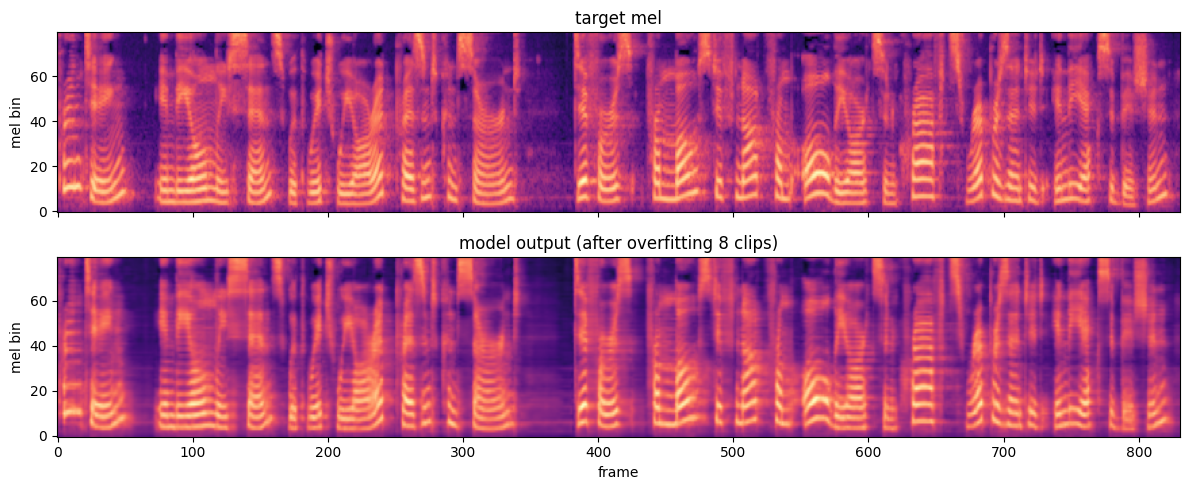

In [ ]:
model.eval()
with torch.no_grad(): o = model(bb['tok'], bb['stress'], dur=bb['dur'])
n = int(bb['mel_len'][0]); mu, sd = ds['train'].mean, ds['train'].std
true = bb['mel'][0, :n].cpu().numpy() * sd + mu; pred = o['mel'][0, :n].cpu().numpy() * sd + mu
fig, ax = plt.subplots(2, 1, figsize=(12, 5), sharex=True)
for a_, m_, t in zip(ax, (true, pred), ('target mel', 'model output (after overfitting 8 clips)')):
    a_.imshow(m_.T, origin='lower', aspect='auto', cmap='magma', vmin=true.min(), vmax=true.max()); a_.set_title(t); a_.set_ylabel('mel bin')
ax[1].set_xlabel('frame'); fig.tight_layout(); fig.savefig(os.path.join(RESULTS, '11_overfit_check.png'), dpi=130); plt.show()

## What to check before moving on
1. `UNIT CHECKS PASSED` and `OVERFIT CHECK PASSED` both printed.
2. Parameter count about 8M; normalised mel mean near 0 and std near 1.
3. In the plot the output looks like the target (same harmonic bands and silences), only slightly blurry.
4. Send the printed output and plot to the group.

**Next:** notebook 12 trains the full model on all train utterances with Drive checkpoints (resumable across Colab sessions).